# Thuật toán K-means

*Bài 8, mục 8.1.3.* K-means chia $N$ điểm thành $K$ cụm bằng cách cực tiểu tổng bình phương khoảng cách từ mỗi điểm tới tâm cụm của nó:
$$\mathcal{L} = \sum_{i=1}^{N}\|\mathbf{x}_i - \boldsymbol{\mu}_{c_i}\|_2^2$$
Thuật toán lặp xen kẽ hai bước: **gán** mỗi điểm vào cụm có tâm gần nhất, **cập nhật** mỗi tâm bằng trung bình các điểm trong cụm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Ví dụ tính tay: 7 điểm, K = 2

Khởi tạo hai tâm bằng điểm B và D.

In [2]:
X = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0], [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
names = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
centers = X[[1, 3]].copy()                   # tâm ban đầu: B và D


def assign(X, centers):
    """Bước gán: chỉ số tâm gần nhất của mỗi điểm."""
    distances = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)   # ma trận N x K
    return distances.argmin(axis=1), distances


def update(X, labels, centers):
    """Bước cập nhật: tâm mới = trung bình các điểm trong cụm (cụm rỗng thì giữ tâm cũ)."""
    return np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else centers[k]
                     for k in range(len(centers))])


def inertia(X, labels, centers):
    """Hàm mất mát L: tổng bình phương khoảng cách tới tâm cụm."""
    return np.sum((X - centers[labels])**2)


for iteration in range(1, 4):
    labels, distances = assign(X, centers)
    print('Vòng lặp %d' % iteration)
    for name, d, label in zip(names, distances, labels):
        print('   %s: khoảng cách tới tâm 1 = %.3f, tới tâm 2 = %.3f -> cụm %d' % (name, d[0], d[1], label + 1))
    new_centers = update(X, labels, centers)
    print('   L (với tâm cũ) = %.3f' % inertia(X, labels, centers))
    print('   Tâm mới:', new_centers.round(3).tolist(), ' L = %.3f' % inertia(X, labels, new_centers))
    if np.allclose(new_centers, centers):
        print('   Tâm không đổi -> hội tụ')
        break
    centers = new_centers

Vòng lặp 1
   A: khoảng cách tới tâm 1 = 1.118, tới tâm 2 = 7.211 -> cụm 1
   B: khoảng cách tới tâm 1 = 0.000, tới tâm 2 = 6.103 -> cụm 1
   C: khoảng cách tới tâm 1 = 2.500, tới tâm 2 = 3.606 -> cụm 1
   D: khoảng cách tới tâm 1 = 6.103, tới tâm 2 = 0.000 -> cụm 2
   E: khoảng cách tới tâm 1 = 3.606, tới tâm 2 = 2.500 -> cụm 2
   F: khoảng cách tới tâm 1 = 4.243, tới tâm 2 = 2.062 -> cụm 2
   G: khoảng cách tới tâm 1 = 3.202, tới tâm 2 = 2.915 -> cụm 2
   L (với tâm cũ) = 26.500
   Tâm mới: [[1.833, 2.333], [4.125, 5.375]]  L = 12.208
Vòng lặp 2
   A: khoảng cách tới tâm 1 = 1.572, tới tâm 2 = 5.376 -> cụm 1
   B: khoảng cách tới tâm 1 = 0.471, tới tâm 2 = 4.276 -> cụm 1
   C: khoảng cách tới tâm 1 = 2.034, tới tâm 2 = 1.777 -> cụm 2
   D: khoảng cách tới tâm 1 = 5.640, tới tâm 2 = 1.846 -> cụm 2
   E: khoảng cách tới tâm 1 = 3.145, tới tâm 2 = 0.729 -> cụm 2
   F: khoảng cách tới tâm 1 = 3.771, tới tâm 2 = 0.530 -> cụm 2
   G: khoảng cách tới tâm 1 = 2.734, tới tâm 2 = 1.075 -> cụm 

## 2. Cài đặt đầy đủ

Khởi tạo $K$ tâm bằng $K$ điểm ngẫu nhiên của dữ liệu; dừng khi các tâm không đổi.

In [3]:
def kmeans(X, K, max_iter=100, seed=0):
    rng = np.random.default_rng(seed)
    centers = X[rng.choice(len(X), K, replace=False)]      # khởi tạo ngẫu nhiên
    history = []
    for _ in range(max_iter):
        labels, _ = assign(X, centers)
        history.append(inertia(X, labels, centers))
        new_centers = update(X, labels, centers)
        if np.allclose(new_centers, centers):
            break
        centers = new_centers
    labels, _ = assign(X, centers)
    return labels, centers, history

Dữ liệu hai chiều 21 điểm của giáo trình (Chương 11):

Tâm cụm:
 [[8.286 2.   ]
 [5.8   6.8  ]
 [4.25  9.5  ]
 [1.6   5.   ]]
L qua các vòng lặp: [86.    20.123 17.979]


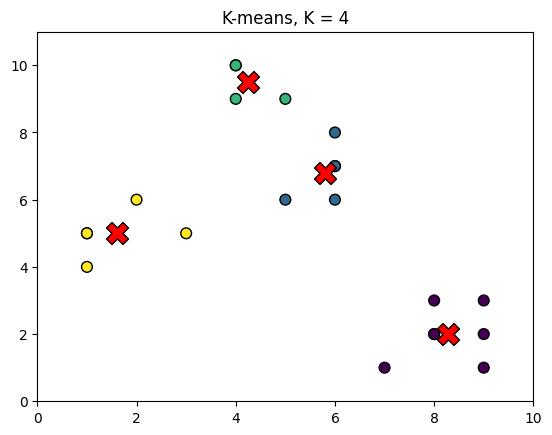

In [4]:
x1 = np.array([3, 1, 1, 2, 1, 6, 6, 6, 5, 6, 7, 8, 9, 8, 9, 9, 8, 4, 4, 5, 4])
x2 = np.array([5, 4, 5, 6, 5, 8, 6, 7, 6, 7, 1, 2, 1, 2, 3, 2, 3, 9, 10, 9, 10])
data = np.column_stack([x1, x2]).astype(float)

labels, centers, history = kmeans(data, K=4, seed=1)
print('Tâm cụm:\n', centers.round(3))
print('L qua các vòng lặp:', np.round(history, 3))
plt.scatter(data[:, 0], data[:, 1], c=labels, cmap='viridis', s=60, edgecolors='k')
plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=250, c='red', edgecolors='k')
plt.title('K-means, K = 4'); plt.xlim(0, 10); plt.ylim(0, 11)
plt.show()

$\mathcal{L}$ giảm sau mỗi vòng lặp (không bao giờ tăng), nên thuật toán luôn hội tụ. Thử đổi `seed=0`: thuật toán vẫn hội tụ nhưng tới một nghiệm kém hơn ($\mathcal{L}$ lớn hơn), xem mục 3.

## 3. Kết quả phụ thuộc vào khởi tạo

K-means chỉ tìm được **cực tiểu địa phương**. Chạy với nhiều khởi tạo khác nhau:

In [5]:
from sklearn.datasets import make_blobs

X_blobs, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=2)
for seed in range(8):
    labels, centers, history = kmeans(X_blobs, K=4, seed=seed)
    print('seed = %d: L = %8.2f sau %2d vòng lặp' % (seed, history[-1], len(history)))

seed = 0: L =   394.87 sau  4 vòng lặp
seed = 1: L =   722.88 sau  6 vòng lặp
seed = 2: L =   394.87 sau  3 vòng lặp
seed = 3: L =   394.87 sau  6 vòng lặp
seed = 4: L =   394.87 sau  5 vòng lặp
seed = 5: L =   723.88 sau  8 vòng lặp
seed = 6: L =   394.87 sau  6 vòng lặp
seed = 7: L =   723.50 sau 10 vòng lặp


Một số khởi tạo cho $\mathcal{L}$ lớn hơn hẳn: hai tâm rơi vào cùng một cụm thật, một tâm phải "gánh" hai cụm. Cách khắc phục:
- chạy nhiều lần với khởi tạo khác nhau và giữ kết quả có $\mathcal{L}$ nhỏ nhất (`n_init` trong scikit-learn);
- **k-means++**: chọn tâm đầu tiên ngẫu nhiên, mỗi tâm tiếp theo được chọn với xác suất tỉ lệ với bình phương khoảng cách tới tâm gần nhất đã chọn, nên các tâm ban đầu nằm rải rác.

## 4. K-means trong scikit-learn

In [6]:
from sklearn.cluster import KMeans

model = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=0)
labels = model.fit_predict(X_blobs)
print('Tâm cụm:\n', model.cluster_centers_.round(3))
print('Hàm mất mát L (inertia_): %.2f' % model.inertia_)
print('Số vòng lặp:', model.n_iter_)
print('Số điểm mỗi cụm:', np.bincount(labels))
print('Dự đoán cụm cho điểm mới (0, 0):', model.predict([[0, 0]]))

Tâm cụm:
 [[-1.37  -3.463]
 [-6.021  2.166]
 [-1.344 -9.453]
 [ 0.873 -1.291]]
Hàm mất mát L (inertia_): 394.87
Số vòng lặp: 5
Số điểm mỗi cụm: [74 75 75 76]
Dự đoán cụm cho điểm mới (0, 0): [3]
